In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import inspect
import json
import sys
import warnings

import numpy as np
import pandas as pd
import scipy
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src/snr_sweep.py").is_file():
    raise RuntimeError("Save this notebook in the project notebooks/ folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import snr_sweep as sweep
from src.manifests import load_manifest

MODELS = tuple(sweep.MODELS)
SNRS = tuple(sweep.SNR_LEVELS)
NOISE_SEEDS = tuple(int(x) for x in sweep.NOISE_SEEDS)
SHOW_SNRS = (20, 50)
N_BOOT = 5000
BOOT_SEED = 20261011
# Change to None for bands describing the actual held-out simulation sample.
N_TARGET = 1113
FLUX_CUT, SIGMA_CUT, MERGE_KMS = 0.85, 3.0, 50.0
HALF_WINDOW_KMS = 300.0
DEPTH_LABELS = ("0.60 <= Fmin < 0.85", "0.30 <= Fmin < 0.60", "Fmin < 0.30")
ASYM_EDGES = np.linspace(-2.0, 2.0, 81)
OUT = ROOT / "outputs/cos_lsf_snr/strong_absorbers"
OUT.mkdir(parents=True, exist_ok=True)

manifest_path = ROOT / "outputs/uvb_mean_flux/manifests/z0_b15_seed42.npz"
manifest = load_manifest(manifest_path)
bundles = np.asarray(manifest["bundles"], dtype=int)
train_ids = np.sort(manifest["train_bundle_ids"].astype(int))
test_ids = np.sort(manifest["test_bundle_ids"].astype(int))
n_los = int(manifest["n_los"])
n_bundle, bundle_size = bundles.shape
n_reference = len(test_ids) * bundle_size
if set(train_ids) & set(test_ids) or set(np.r_[train_ids, test_ids]) != set(range(n_bundle)):
    raise RuntimeError("Invalid frozen bundle partition.")
if np.unique(bundles).size != bundles.size or bundles.min() < 0 or bundles.max() >= n_los:
    raise RuntimeError("Manifest contains repeated or out-of-range LOS IDs.")
los_bundle = np.full(n_los, -1, dtype=np.int32)
los_split = np.full(n_los, -1, dtype=np.int8)
los_bundle[bundles.ravel()] = np.repeat(np.arange(n_bundle), bundle_size)
los_split[bundles[train_ids].ravel()] = 0
los_split[bundles[test_ids].ravel()] = 1
used_los = np.flatnonzero(los_split >= 0)
test_position = np.full(n_bundle, -1, dtype=int)
test_position[test_ids] = np.arange(len(test_ids))
missing = [str(ROOT / "outputs/cos_lsf_snr/snr_sweep/clean_flux" / f"{m}.npz")
           for m in MODELS if not (ROOT / "outputs/cos_lsf_snr/snr_sweep/clean_flux" / f"{m}.npz").is_file()]
if missing:
    raise FileNotFoundError("Existing clean LP1 caches are required:\n" + "\n".join(missing))
if MODELS[0] != "EX0" or not set(SHOW_SNRS).issubset(SNRS):
    raise RuntimeError("Expected EX0 first and S/N 20, 50 in the sweep.")
band_scale = np.sqrt(n_reference / (n_reference if N_TARGET is None else N_TARGET))
band_scope = (f"{n_reference:,} held-out chunks" if N_TARGET is None else
              f"nominal {N_TARGET:,}-chunk scaling")
print(f"Export: {len(used_los):,} unique LOS/model; {len(SNRS)} S/N levels; {len(NOISE_SEEDS)} noise seeds.")
print(f"Figures: test split only ({n_reference:,} chunks/model). Bands: {band_scope}.")


Export: 9,990 unique LOS/model; 6 S/N levels; 3 noise seeds.
Figures: test split only (2,010 chunks/model). Bands: nominal 1,113-chunk scaling.


In [2]:
def smooth_three(flux, sigma, *, periodic=True, valid=None):
    """Arithmetic 3-bin mean and its independent-pixel propagated error.

    For real data later: pass a common uniform velocity grid, per-bin errors,
    valid=False for masked/gap bins, and periodic=False. Rebinning covariance
    must be checked before using this independent-error propagation.
    """
    flux = np.asarray(flux, dtype=float)
    if flux.ndim != 1 or flux.size < 3:
        raise ValueError("Expected a 1D flux array with at least 3 pixels.")
    error = np.broadcast_to(np.asarray(sigma, dtype=float), flux.shape)
    good = np.isfinite(flux) & np.isfinite(error) & (error > 0)
    if valid is not None:
        good &= np.asarray(valid, dtype=bool)
    safe_flux = np.where(good, flux, 0.0)
    safe_var = np.where(good, error**2, 0.0)
    fs = (np.roll(safe_flux, 1) + safe_flux + np.roll(safe_flux, -1)) / 3
    es = np.sqrt(np.roll(safe_var, 1) + safe_var + np.roll(safe_var, -1)) / 3
    usable = np.roll(good, 1) & good & np.roll(good, -1)
    if not periodic:
        usable[[0, -1]] = False
    return fs, es, usable


def local_minima(values, usable, *, periodic):
    """One midpoint per plateau; never find peaks through NaNs or gaps."""
    if periodic:
        if not usable.all():
            raise ValueError("Periodic mock detection requires every pixel to be valid.")
        n = len(values)
        peaks, _ = find_peaks(-np.tile(values, 3))
        return peaks[(peaks >= n) & (peaks < 2*n)] - n
    # Search each continuous usable segment separately; segment endpoints are
    # not candidates because they lack two usable neighboring smoothed bins.
    edges = np.flatnonzero(np.diff(np.r_[False, usable, False]))
    candidates = []
    for start, stop in edges.reshape(-1, 2):
        peaks, _ = find_peaks(-values[start:stop])
        candidates.extend((peaks + start).tolist())
    return np.asarray(candidates, dtype=int)


def merge_minima(candidates, fs, dv, *, periodic, merge_kms=MERGE_KMS):
    """Deepest-first suppression within <=50 km/s, including circular edges.

    Not transitive chaining: A can suppress B, while C survives if farther
    than the merge radius from every retained center. Ties use pixel index.
    """
    candidates = np.asarray(candidates, dtype=int)
    order = np.lexsort((candidates, fs[candidates]))
    retained = []
    for index in candidates[order]:
        distances = np.abs(np.asarray(retained, dtype=int) - index)
        if periodic:
            distances = np.minimum(distances, len(fs) - distances)
        if not retained or np.all(distances * dv > merge_kms):
            retained.append(int(index))
    return np.asarray(sorted(retained), dtype=int)


def detect_minima(flux, sigma, dv, *, periodic=True, valid=None):
    fs, es, usable = smooth_three(flux, sigma, periodic=periodic, valid=valid)
    centers = local_minima(fs, usable, periodic=periodic)
    significance = (1.0 - fs[centers]) / es[centers]
    centers = centers[(fs[centers] < FLUX_CUT) & (significance >= SIGMA_CUT)]
    centers = merge_minima(centers, fs, dv, periodic=periodic)
    return centers, fs, es


def depth_bin(fmin):
    """Depth class is determined by the noisy, smoothed detection value."""
    fmin = np.asarray(fmin)
    return np.where(fmin >= 0.6, 0, np.where(fmin >= 0.3, 1, 2)).astype(np.int8)


def window_geometry(dv):
    half = int(np.floor(HALF_WINDOW_KMS / dv))
    offsets = np.arange(-half, half+1)
    velocity = offsets * dv
    lower, upper = velocity - dv/2, velocity + dv/2
    blue = np.maximum(0.0, np.minimum(upper, 0.0) - np.maximum(lower, -HALF_WINDOW_KMS))
    red = np.maximum(0.0, np.minimum(upper, HALF_WINDOW_KMS) - np.maximum(lower, 0.0))
    np.testing.assert_allclose([blue.sum(), red.sum()], HALF_WINDOW_KMS, atol=1e-10)
    return offsets, velocity, blue, red


def equivalent_widths(windows, sigma, blue_width, red_width):
    """Unclipped flux; exact +/-300 km/s support; half central bin each side.

    EW errors below assume independent pixels and a fixed selected center.
    They are denominator-stability diagnostics, not post-selection p values.
    A need not lie in [-1, 1] for noisy, unclipped profiles.
    """
    absorption = 1.0 - np.asarray(windows, dtype=float)
    eb, er = absorption @ blue_width, absorption @ red_width
    ew = eb + er
    sigma_ew = np.broadcast_to(sigma, ew.shape) * np.linalg.norm(blue_width + red_width)
    asymmetry = np.divide(er-eb, ew, out=np.full_like(ew, np.nan), where=ew > 0)
    return eb, er, ew, sigma_ew, asymmetry


def get_windows(flux, centers, offsets):
    return np.asarray(flux)[(centers[:, None] + offsets[None, :]) % len(flux)]


def json_plain(value):
    if isinstance(value, dict):
        return {str(k): json_plain(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_plain(v) for v in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    return value


In [3]:
parts = []
source_metadata = {}
seed_rows, asym_rows = [], []
moments = {}
dv = None

for m, model in enumerate(MODELS):
    # This validates the existing cache against calibration and source files.
    clean_all, current_dv, metadata = sweep.cache_lp1_flux(model, ROOT)
    if clean_all.shape[0] != n_los or not np.all(np.isfinite(clean_all)):
        raise RuntimeError(f"Invalid clean cache for {model}.")
    if dv is None:
        dv = float(current_dv)
        n_pixel = clean_all.shape[1]
        path_per_los = n_pixel * dv
        offsets, velocity, blue_width, red_width = window_geometry(dv)
        n_window = len(offsets)
        if n_window != 87 or not np.isclose(path_per_los, 2500.0):
            raise RuntimeError("Expected 87-bin windows on the 2500 km/s LP1 grid.")
        shape = (len(SNRS), len(NOISE_SEEDS), len(MODELS), len(test_ids), 3)
        count = np.zeros(shape, dtype=np.int32)
        profile_sum = np.zeros(shape + (n_window,), dtype=float)
        clean_profile_sum = np.zeros_like(profile_sum)
    elif clean_all.shape[1] != n_pixel or not np.isclose(current_dv, dv, rtol=0, atol=1e-12):
        raise RuntimeError("All models must have identical grids.")
    source_metadata[model] = metadata

    for s, snr in enumerate(SNRS):
        sigma = float(sweep.sigma_per_bin(snr))
        for r, seed in enumerate(NOISE_SEEDS):
            # Preserve exact S/N sweep draws: noise on all LOS, original order.
            noisy_all = sweep.add_noise(clean_all, snr, model=model, noise_seed=seed)
            records = {key: [] for key in ("windows", "clean_windows_at_noisy_centers", "los_id",
                                          "center_pixel", "fmin", "significance", "wraps_boundary",
                                          "nearest_detection_kms")}
            for los in used_los:
                centers, fs, es = detect_minima(noisy_all[los], sigma, dv)
                n = len(centers)
                if n == 0:
                    continue
                windows = get_windows(noisy_all[los], centers, offsets)
                clean_windows = get_windows(clean_all[los], centers, offsets)
                fmin = fs[centers]
                depths = depth_bin(fmin)
                records["windows"].append(windows.astype(np.float32))
                records["clean_windows_at_noisy_centers"].append(clean_windows.astype(np.float32))
                records["los_id"].append(np.full(n, los, dtype=np.int32))
                records["center_pixel"].append(centers.astype(np.int16))
                records["fmin"].append(fmin)
                records["significance"].append((1-fmin) / es[centers])
                records["wraps_boundary"].append((centers+offsets[0] < 0) | (centers+offsets[-1] >= n_pixel))
                sep = np.abs(centers[:, None] - centers[None, :])
                sep = np.minimum(sep, n_pixel-sep).astype(float) * dv
                np.fill_diagonal(sep, np.inf)
                nearest = sep.min(axis=1)
                nearest[~np.isfinite(nearest)] = np.nan
                records["nearest_detection_kms"].append(nearest)
                if los_split[los] == 1:
                    b = test_position[los_bundle[los]]
                    for d in range(3):
                        selected = depths == d
                        count[s, r, m, b, d] += selected.sum()
                        profile_sum[s, r, m, b, d] += windows[selected].sum(axis=0)
                        clean_profile_sum[s, r, m, b, d] += clean_windows[selected].sum(axis=0)

            if records["windows"]:
                data = {key: np.concatenate(value) for key, value in records.items()}
            else:
                data = {"windows": np.empty((0, n_window), dtype=np.float32),
                        "clean_windows_at_noisy_centers": np.empty((0, n_window), dtype=np.float32)}
                for key, dtype in (("los_id", "i4"), ("center_pixel", "i2"), ("fmin", "f8"),
                                   ("significance", "f8"), ("wraps_boundary", "?"),
                                   ("nearest_detection_kms", "f8")):
                    data[key] = np.empty(0, dtype=dtype)
            n = len(data["los_id"])
            data.update({
                "labels": np.full(n, m, dtype=np.int8),
                "group_id": data["los_id"],
                "split": los_split[data["los_id"]],
                "bundle_id": los_bundle[data["los_id"]],
                "snr_resel": np.full(n, snr, dtype=np.int16),
                "sigma_bin": np.full(n, sigma, dtype=np.float32),
                "noise_seed": np.full(n, seed, dtype=np.int64),
                "depth_bin": depth_bin(data["fmin"]),
                "depth": 1-data["fmin"],
            })
            eb, er, ew, eew, a = equivalent_widths(data["windows"], sigma, blue_width, red_width)
            data.update({"ew_blue_kms": eb, "ew_red_kms": er, "ew_kms": ew,
                         "ew_sigma_kms": eew, "asymmetry": a,
                         "asymmetry_valid": ew > 0, "ew_ge_3sigma": ew >= 3*eew})
            parts.append(data)
            test_counts = count[s, r, m].sum(axis=0)
            for d in range(3):
                seed_rows.append({"SNR": snr, "noise_seed": seed, "model": model,
                                  "depth_bin": d, "depth_label": DEPTH_LABELS[d],
                                  "n_test_absorbers": int(test_counts[d])})
            seed_rows.append({"SNR": snr, "noise_seed": seed, "model": model,
                              "depth_bin": -1, "depth_label": "all",
                              "n_test_absorbers": int(test_counts.sum())})
            print(f"{model}, S/N {snr:2d}, seed {seed}: {n:,} windows; {int(test_counts.sum()):,} test", flush=True)
            del noisy_all, records, data
    del clean_all

catalog = {key: np.concatenate([part[key] for part in parts]) for key in parts[0]}
del parts
seed_counts = pd.DataFrame(seed_rows)
seed_counts["rate_per_1e4_kms"] = seed_counts.n_test_absorbers * 1e4 / (n_reference*path_per_los)
# Every noise realization, model and window from one LOS has one split.
np.testing.assert_array_equal(catalog["split"], los_split[catalog["los_id"]])
np.testing.assert_array_equal(catalog["bundle_id"], los_bundle[catalog["los_id"]])
for split_code in (0, 1):
    if not np.isin(catalog["los_id"][catalog["split"] == split_code],
                   bundles[train_ids if split_code == 0 else test_ids]).all():
        raise RuntimeError("Window split leakage.")
print(f"\nTotal exported examples: {len(catalog['labels']):,}; grid centres: {velocity[0]:.3f} to {velocity[-1]:.3f} km/s.")
print("EW integration uses exactly -300 to +300 km/s, including partial edge bins.")


EX0: reused EX0.npz
EX0, S/N 10, seed 20260929: 21,703 windows; 4,343 test
EX0, S/N 10, seed 20260930: 21,939 windows; 4,399 test
EX0, S/N 10, seed 20261001: 21,784 windows; 4,330 test
EX0, S/N 15, seed 20260929: 27,344 windows; 5,431 test
EX0, S/N 15, seed 20260930: 27,469 windows; 5,512 test
EX0, S/N 15, seed 20261001: 27,348 windows; 5,479 test
EX0, S/N 20, seed 20260929: 21,810 windows; 4,338 test
EX0, S/N 20, seed 20260930: 21,841 windows; 4,358 test
EX0, S/N 20, seed 20261001: 21,808 windows; 4,347 test
EX0, S/N 30, seed 20260929: 18,069 windows; 3,561 test
EX0, S/N 30, seed 20260930: 18,031 windows; 3,620 test
EX0, S/N 30, seed 20261001: 18,173 windows; 3,615 test
EX0, S/N 50, seed 20260929: 16,453 windows; 3,284 test
EX0, S/N 50, seed 20260930: 16,416 windows; 3,283 test
EX0, S/N 50, seed 20261001: 16,488 windows; 3,296 test
EX0, S/N 80, seed 20260929: 15,724 windows; 3,136 test
EX0, S/N 80, seed 20260930: 15,708 windows; 3,135 test
EX0, S/N 80, seed 20261001: 15,722 windows; 3

In [4]:
rng = np.random.default_rng(BOOT_SEED)
weights = rng.multinomial(len(test_ids), np.full(len(test_ids), 1/len(test_ids)), size=N_BOOT).astype(float)


def safe_divide(num, den):
    return np.divide(num, den, out=np.full(np.broadcast_shapes(num.shape, den.shape), np.nan), where=den > 0)


def bootstrap_sum(sums):
    # sums: model, bundle, ... . The same draws apply to all models/seeds.
    flat = np.moveaxis(sums, 1, 0).reshape(len(test_ids), -1)
    return (weights @ flat).reshape((N_BOOT, len(MODELS)) + sums.shape[2:])


def percentile_bounds(center, residuals):
    """Pool within-seed residuals: seeds stabilize the mean, not sample size."""
    valid_fraction = np.isfinite(residuals).mean(axis=0)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        q = np.nanquantile(residuals, [0.025, 0.975], axis=0)
    bounds = center[None] + band_scale*q
    bounds[:, valid_fraction < 0.95] = np.nan
    return bounds, valid_fraction


def stack_bootstrap(sums, counts):
    # sums: seed, model, bundle, depth, velocity; counts lacks velocity.
    seed_mean = safe_divide(sums.sum(axis=2), counts.sum(axis=2)[..., None])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        center = np.nanmean(seed_mean, axis=0)
    residuals, delta_residuals = [], []
    for r in range(len(NOISE_SEEDS)):
        draws = safe_divide(bootstrap_sum(sums[r]), bootstrap_sum(counts[r])[..., None])
        residuals.append(draws - seed_mean[r][None])
        seed_delta = seed_mean[r] - seed_mean[r, :1]
        delta_residuals.append(draws - draws[:, :1] - seed_delta[None])
    bounds, valid_fraction = percentile_bounds(center, np.concatenate(residuals))
    delta = center - center[:1]
    delta_bounds, delta_valid = percentile_bounds(delta, np.concatenate(delta_residuals))
    return {"mean": center, "ci": bounds, "difference": delta, "difference_ci": delta_bounds,
            "valid_bootstrap_fraction": valid_fraction, "difference_valid_fraction": delta_valid}


rate_rows, contrast_rows, stack_results = [], [], {}
rate_factor = 1e4 / (n_reference * path_per_los)
for s, snr in enumerate(SNRS):
    # Separate total category plus the three mutually exclusive depth bins.
    counts4 = np.concatenate([count[s].sum(axis=-1, keepdims=True), count[s]], axis=-1)
    seed_rate = counts4.sum(axis=2) * rate_factor
    mean_rate = seed_rate.mean(axis=0)
    log_residuals, difference_residuals = [], []
    for r in range(len(NOISE_SEEDS)):
        draws = bootstrap_sum(counts4[r]) * rate_factor
        with np.errstate(divide="ignore", invalid="ignore"):
            logs = np.log(draws / seed_rate[r][None])
        logs[~np.isfinite(logs)] = np.nan
        log_residuals.append(logs)
        difference_residuals.append(draws-draws[:, :1] - (seed_rate[r]-seed_rate[r, :1])[None])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        residual_pool = np.concatenate(log_residuals)
        q = np.nanquantile(residual_pool, [0.025, 0.975], axis=0)
    rate_ci = mean_rate[None] * np.exp(band_scale*q)
    rate_ci[:, np.isfinite(residual_pool).mean(axis=0) < 0.95] = np.nan
    differences = mean_rate - mean_rate[:1]
    difference_ci, _ = percentile_bounds(differences, np.concatenate(difference_residuals))
    for m, model in enumerate(MODELS):
        for j, label in enumerate(("all",) + DEPTH_LABELS):
            rate_rows.append({"SNR": snr, "model": model, "depth_bin": j-1, "depth_label": label,
                              "rate_per_1e4_kms": mean_rate[m,j], "low": rate_ci[0,m,j], "high": rate_ci[1,m,j],
                              "seed_min": seed_rate[:,m,j].min(), "seed_max": seed_rate[:,m,j].max(),
                              "effective_Fmin_upper": min(FLUX_CUT, 1-SIGMA_CUT*sweep.sigma_per_bin(snr)/np.sqrt(3)),
                              "mean_n_test_absorbers": counts4[:,m,:,j].sum(axis=-1).mean()})
            if m > 0:
                contrast_rows.append({"SNR": snr, "model": model, "reference": "EX0", "depth_label": label,
                                      "difference_per_1e4_kms": differences[m,j],
                                      "low": difference_ci[0,m,j], "high": difference_ci[1,m,j]})
    if snr in SHOW_SNRS:
        result = stack_bootstrap(profile_sum[s], count[s])
        clean_mean = safe_divide(clean_profile_sum[s].sum(axis=2), count[s].sum(axis=2)[...,None])
        result["clean_at_noisy_centers"] = np.nanmean(clean_mean, axis=0)
        # Same selected objects and noisy centers isolate additive noise selection.
        bias_result = stack_bootstrap(profile_sum[s]-clean_profile_sum[s], count[s])
        result["selection_bias"] = bias_result["mean"]
        result["selection_bias_ci"] = bias_result["ci"]
        result["bias_difference"] = bias_result["difference"]
        result["bias_difference_ci"] = bias_result["difference_ci"]
        result["mean_counts"] = count[s].sum(axis=2).mean(axis=0)
        stack_results[snr] = result
    print(f"Bootstrap complete: S/N {snr}", flush=True)
rates = pd.DataFrame(rate_rows)
rate_contrasts = pd.DataFrame(contrast_rows)


Bootstrap complete: S/N 10
Bootstrap complete: S/N 15
Bootstrap complete: S/N 20
Bootstrap complete: S/N 30
Bootstrap complete: S/N 50
Bootstrap complete: S/N 80


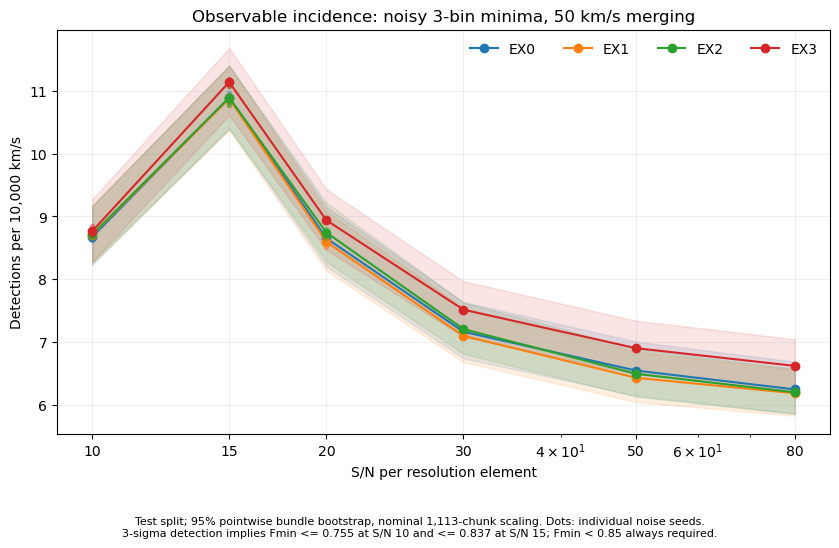

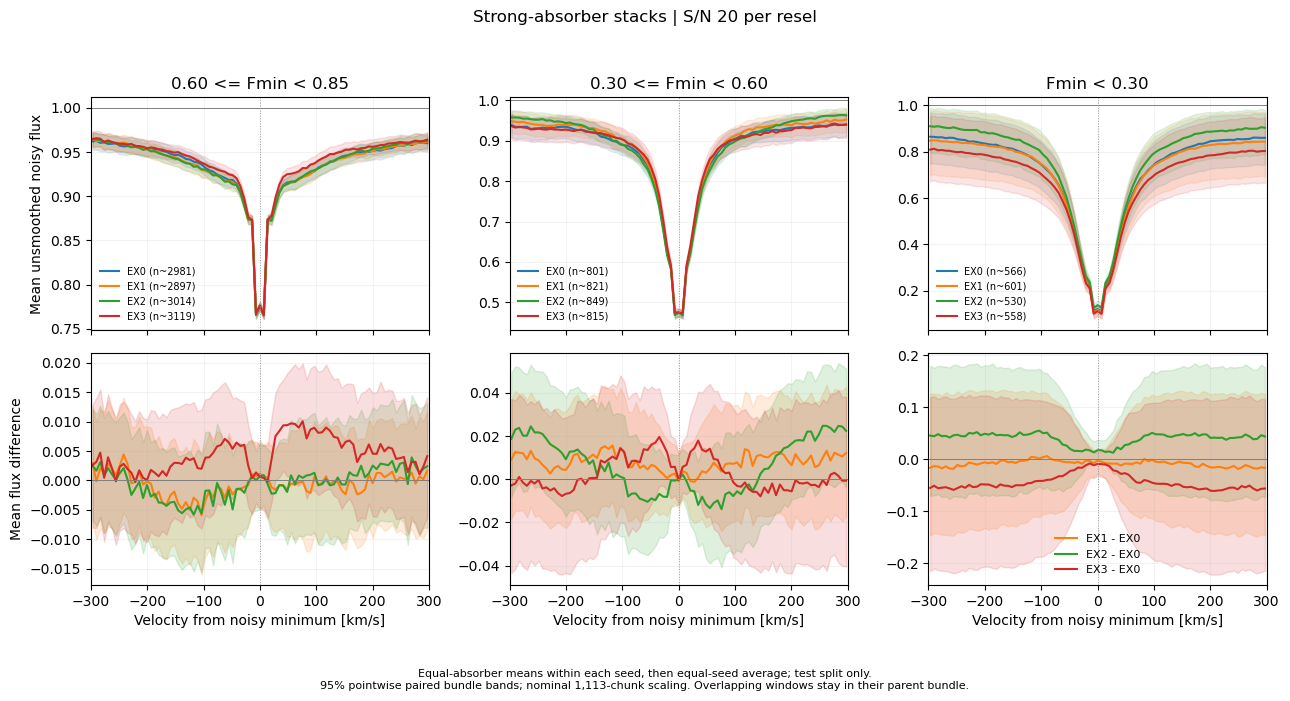

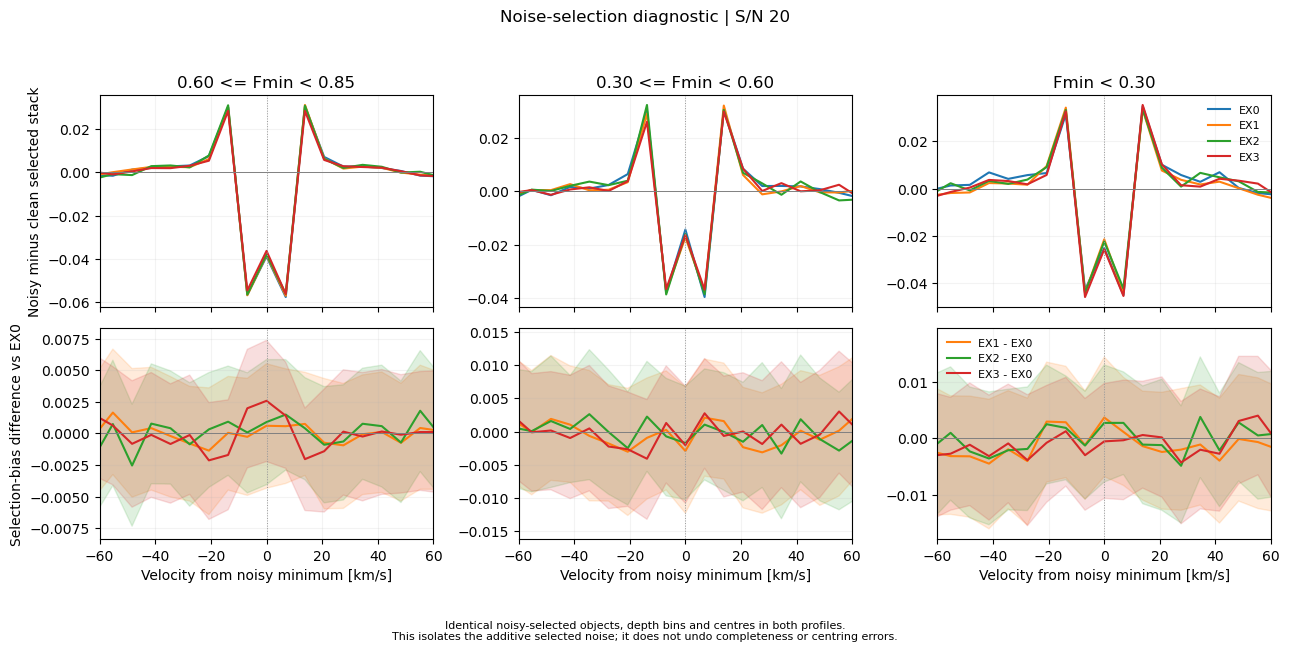

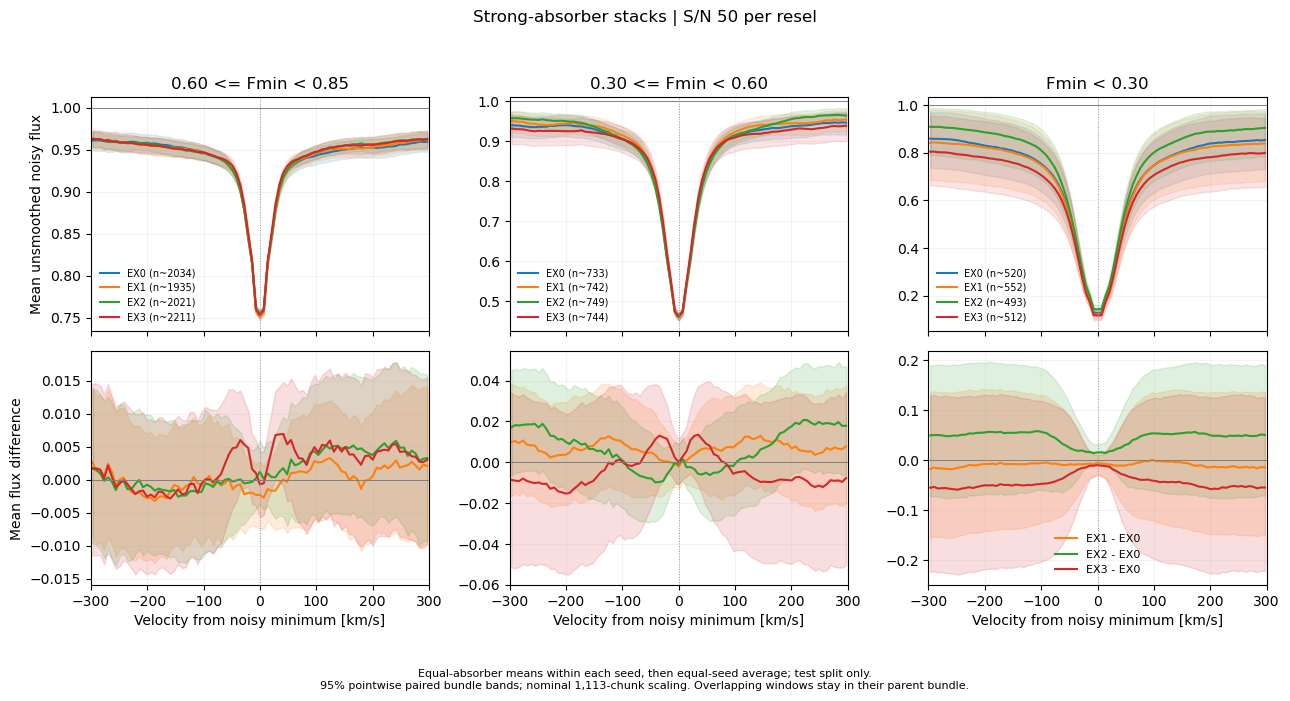

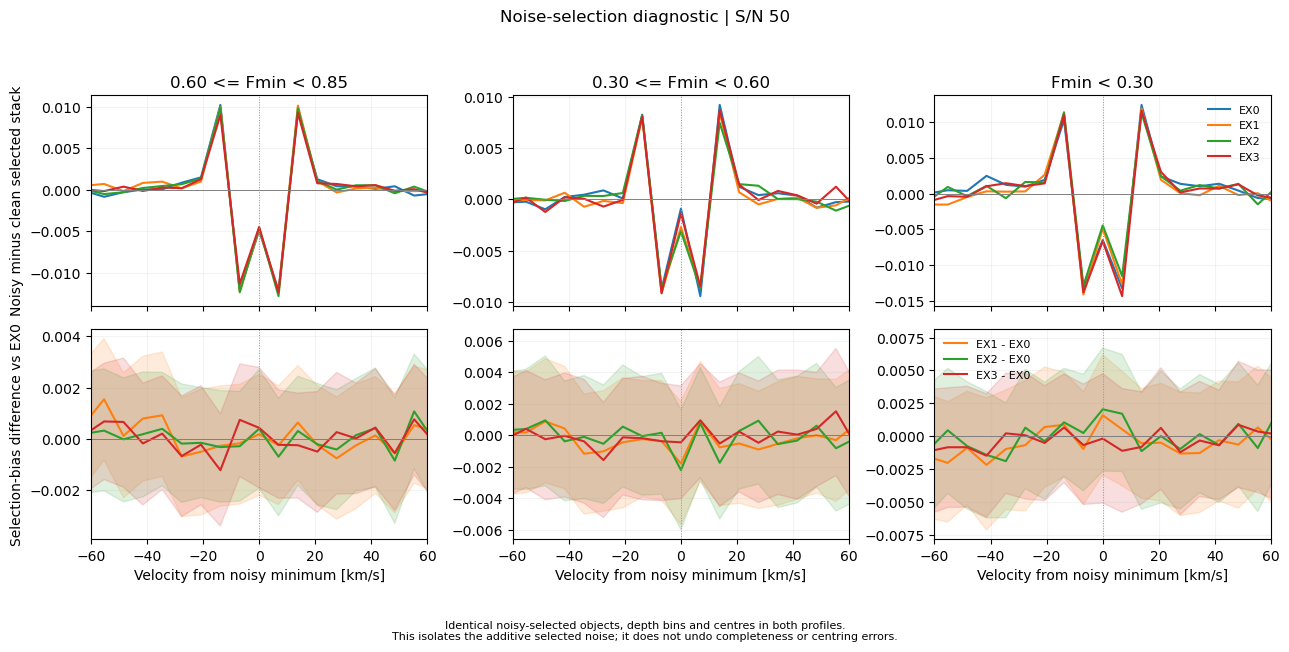

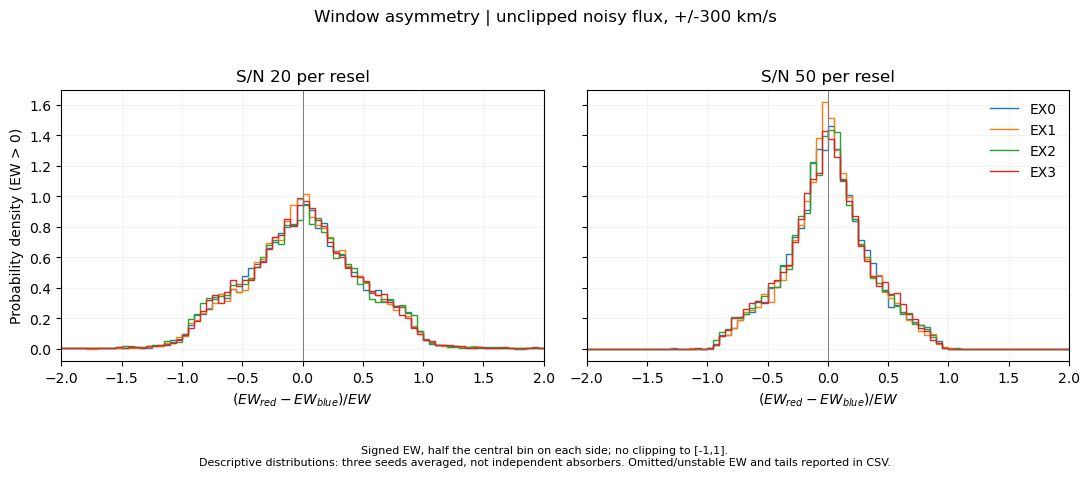

In [5]:
colors = plt.get_cmap("tab10").colors[:len(MODELS)]


def save_figure(figure, name):
    figure.savefig(OUT / f"{name}.png", dpi=180, bbox_inches="tight")
    figure.savefig(OUT / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(figure)


fig, ax = plt.subplots(figsize=(8.5, 5.5))
for m, model in enumerate(MODELS):
    frame = rates[(rates.model == model) & (rates.depth_label == "all")].sort_values("SNR")
    x, y, low, high = (frame[key].to_numpy() for key in ("SNR", "rate_per_1e4_kms", "low", "high"))
    ax.plot(x, y, "o-", color=colors[m], label=model)
    ax.fill_between(x, low, high, color=colors[m], alpha=0.12)
    for seed in NOISE_SEEDS:
        seed_frame = seed_counts[(seed_counts.model == model) & (seed_counts.depth_label == "all") &
                                 (seed_counts.noise_seed == seed)].sort_values("SNR")
        ax.plot(seed_frame.SNR, seed_frame.rate_per_1e4_kms, ".", color=colors[m], alpha=0.35)
ax.set(xlabel="S/N per resolution element", ylabel="Detections per 10,000 km/s", xscale="log",
       title="Observable incidence: noisy 3-bin minima, 50 km/s merging")
ax.set_xticks(SNRS, labels=[str(x) for x in SNRS])
ax.grid(alpha=0.2)
ax.legend(frameon=False, ncol=4)
fig.text(0.5, 0.015, f"Test split; 95% pointwise bundle bootstrap, {band_scope}. Dots: individual noise seeds.\n"
         "3-sigma detection implies Fmin <= 0.755 at S/N 10 and <= 0.837 at S/N 15; Fmin < 0.85 always required.",
         ha="center", fontsize=8)
fig.tight_layout(rect=(0,0.09,1,1))
save_figure(fig, "observable_incidence")

stack_rows = []
for snr in SHOW_SNRS:
    result = stack_results[snr]
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
    for d, label in enumerate(DEPTH_LABELS):
        axes[0,d].set_title(label)
        for m, model in enumerate(MODELS):
            y, ci = result["mean"][m,d], result["ci"][:,m,d]
            axes[0,d].plot(velocity, y, color=colors[m], label=f"{model} (n~{result['mean_counts'][m,d]:.0f})")
            axes[0,d].fill_between(velocity, ci[0], ci[1], color=colors[m], alpha=0.12)
            if m > 0:
                delta, dci = result["difference"][m,d], result["difference_ci"][:,m,d]
                axes[1,d].plot(velocity, delta, color=colors[m], label=f"{model} - EX0")
                axes[1,d].fill_between(velocity, dci[0], dci[1], color=colors[m], alpha=0.15)
            stack_rows.append(pd.DataFrame({"SNR": snr, "model": model, "depth_bin": d,
                                           "velocity_kms": velocity, "mean_flux": y, "low": ci[0], "high": ci[1],
                                           "difference_vs_EX0": result["difference"][m,d],
                                           "difference_low": result["difference_ci"][0,m,d],
                                           "difference_high": result["difference_ci"][1,m,d],
                                           "clean_at_noisy_centers": result["clean_at_noisy_centers"][m,d],
                                           "noise_selection_bias": result["selection_bias"][m,d],
                                           "bias_difference_vs_EX0": result["bias_difference"][m,d]}))
        axes[0,d].axhline(1, color="0.5", lw=0.7)
        axes[1,d].axhline(0, color="0.5", lw=0.7)
        axes[1,d].set_xlabel("Velocity from noisy minimum [km/s]")
        axes[0,d].legend(fontsize=7, frameon=False)
    axes[0,0].set_ylabel("Mean unsmoothed noisy flux")
    axes[1,0].set_ylabel("Mean flux difference")
    for ax in axes.flat:
        ax.axvline(0, color="0.6", lw=0.7, ls=":")
        ax.set_xlim(-300,300)
        ax.grid(alpha=0.15)
    axes[1,2].legend(fontsize=8, frameon=False)
    fig.suptitle(f"Strong-absorber stacks | S/N {snr} per resel")
    fig.text(0.5,0.01, f"Equal-absorber means within each seed, then equal-seed average; test split only.\n"
             f"95% pointwise paired bundle bands; {band_scope}. Overlapping windows stay in their parent bundle.",
             ha="center", fontsize=8)
    fig.tight_layout(rect=(0,0.075,1,0.95))
    save_figure(fig, f"stack_profiles_snr{snr}")

    fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
    for d, label in enumerate(DEPTH_LABELS):
        axes[0,d].set_title(label)
        for m, model in enumerate(MODELS):
            axes[0,d].plot(velocity, result["selection_bias"][m,d], color=colors[m], label=model)
            if m > 0:
                y = result["bias_difference"][m,d]
                ci = result["bias_difference_ci"][:,m,d]
                axes[1,d].plot(velocity, y, color=colors[m], label=f"{model} - EX0")
                axes[1,d].fill_between(velocity, ci[0], ci[1], color=colors[m], alpha=0.15)
        for ax in axes[:,d]:
            ax.axhline(0,color="0.5",lw=0.7)
            ax.axvline(0,color="0.6",lw=0.7,ls=":")
            ax.set_xlim(-60,60)
            ax.grid(alpha=0.15)
        axes[1,d].set_xlabel("Velocity from noisy minimum [km/s]")
    axes[0,0].set_ylabel("Noisy minus clean selected stack")
    axes[1,0].set_ylabel("Selection-bias difference vs EX0")
    axes[0,2].legend(frameon=False,fontsize=8)
    axes[1,2].legend(frameon=False,fontsize=8)
    fig.suptitle(f"Noise-selection diagnostic | S/N {snr}")
    fig.text(0.5,0.01,"Identical noisy-selected objects, depth bins and centres in both profiles.\n"
             "This isolates the additive selected noise; it does not undo completeness or centring errors.",
             ha="center",fontsize=8)
    fig.tight_layout(rect=(0,0.075,1,0.95))
    save_figure(fig,f"selection_bias_snr{snr}")

fig, axes = plt.subplots(1, len(SHOW_SNRS), figsize=(11,4.7), sharey=True, squeeze=False)
test_mask = catalog["split"] == 1
for s, snr in enumerate(SNRS):
    for m, model in enumerate(MODELS):
        histogram_seeds = []
        for seed in NOISE_SEEDS:
            select = test_mask & (catalog["snr_resel"] == snr) & (catalog["labels"] == m) & (catalog["noise_seed"] == seed)
            values = catalog["asymmetry"][select]
            finite = np.isfinite(values)
            positive = values[finite]
            reliable = catalog["ew_ge_3sigma"][select] & finite
            stable = values[reliable]
            hist = np.histogram(positive, ASYM_EDGES)[0]
            histogram_seeds.append(hist / (max(len(positive),1)*np.diff(ASYM_EDGES)))
            asym_rows.append({"SNR":snr,"model":model,"noise_seed":seed,"n_test_absorbers":int(select.sum()),
                              "n_EW_positive":int(finite.sum()),"n_EW_ge_3sigma":int(reliable.sum()),
                              "nonpositive_EW_fraction":float(1-finite.mean()) if finite.size else np.nan,
                              "outside_plot_fraction":float(np.mean((positive<ASYM_EDGES[0]) | (positive>ASYM_EDGES[-1]))) if positive.size else np.nan,
                              "median_A":float(np.median(positive)) if positive.size else np.nan,
                              "median_abs_A":float(np.median(np.abs(positive))) if positive.size else np.nan,
                              "median_abs_A_EW_ge_3sigma":float(np.median(np.abs(stable))) if stable.size else np.nan})
        if snr in SHOW_SNRS:
            ax = axes[0, SHOW_SNRS.index(snr)]
            ax.stairs(np.mean(histogram_seeds,axis=0),ASYM_EDGES,baseline=None,color=colors[m],label=model)
            ax.set(title=f"S/N {snr} per resel", xlabel=r"$(EW_{red}-EW_{blue})/EW$",xlim=(-2,2))
            ax.axvline(0,color="0.5",lw=0.7)
            ax.grid(alpha=0.15)
axes[0,0].set_ylabel("Probability density (EW > 0)")
axes[0,-1].legend(frameon=False)
fig.suptitle("Window asymmetry | unclipped noisy flux, +/-300 km/s")
fig.text(0.5,0.01,"Signed EW, half the central bin on each side; no clipping to [-1,1].\n"
         "Descriptive distributions: three seeds averaged, not independent absorbers. Omitted/unstable EW and tails reported in CSV.",
         ha="center",fontsize=8)
fig.tight_layout(rect=(0,0.10,1,0.95))
save_figure(fig,"asymmetry_distributions")
asymmetry_summary = pd.DataFrame(asym_rows)


In [6]:
helper_source = "\n\n".join(inspect.getsource(fn) for fn in
    (smooth_three, local_minima, merge_minima, detect_minima, depth_bin, window_geometry,
     equivalent_widths, get_windows, safe_divide, bootstrap_sum, percentile_bounds, stack_bootstrap))
provenance = {
    "schema_version":1, "created_utc":datetime.now(timezone.utc).isoformat(),
    "models":MODELS, "snrs_per_resel":SNRS, "noise_seeds":NOISE_SEEDS,
    "source_metadata":source_metadata, "manifest_path":str(manifest_path.relative_to(ROOT)),
    "manifest_sha256":hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
    "code_sha256":hashlib.sha256(helper_source.encode()).hexdigest(),
    "versions":{"numpy":np.__version__,"scipy":scipy.__version__,"pandas":pd.__version__},
    "detection":{"smoothing":"3-bin arithmetic boxcar", "flux_cut_strict":FLUX_CUT,
                 "min_significance_inclusive":SIGMA_CUT, "smoothed_sigma":"sigma_bin/sqrt(3); independent noise",
                 "merge_radius_inclusive_kms":MERGE_KMS,
                 "merge_rule":"Deepest-first nonmaximum suppression; circular distance; ties by pixel index; no transitive chaining",
                 "plateau_rule":"One midpoint, rounded down for even plateau length"},
    "windows":{"periodic":True,"n_bins":n_window,"dv_kms":dv,"velocity_length_per_los_kms":path_per_los,
               "center_range_kms":[float(velocity[0]),float(velocity[-1])],
               "outer_pixel_edges_kms":[float(velocity[0]-dv/2),float(velocity[-1]+dv/2)],
               "flux":"Unsmoothed noisy continuum-normalized flux; no clipping or per-window fitting",
               "storage_dtype":"Window arrays float32; measurements and bundle sums float64",
               "clean_windows":"Same noisy-selected centers and objects; simulation-only diagnostics, not ML inputs"},
    "depth":{"Fmin":"Noisy 3-bin smoothed flux at the detection center","depth":"1-Fmin", "labels":DEPTH_LABELS},
    "asymmetry":{"EW":"Sum (1-F) times pixel overlap width in exactly +/-300 km/s; units km/s",
                 "A":"(EW_red-EW_blue)/(EW_red+EW_blue)","central_bin":"Half to each side",
                 "validity":"A is NaN for EW<=0; flux and A are not clipped; ew_ge_3sigma is a diagnostic flag",
                 "EW_sigma":"Independent pixel errors at fixed selected center; not a selection-corrected significance",
                 "interpretation":"Includes blends/neighbors within the window and selection/centering effects"},
    "split":{"0":"train","1":"test","unused_manifest_los":"excluded",
             "group_id":"los_id is shared across models, S/N, seeds and overlapping windows",
             "resampling_unit":"whole original bundle_id; including bundles with zero detections",
             "ML_policy":"Never random-split windows; tune or validate on grouped training LOS/bundles only; preserve test split",
             "n_train_los":int(len(train_ids)*bundle_size),"n_test_los":n_reference},
    "bootstrap":{"draws":N_BOOT,"seed":BOOT_SEED,"nominal_target_chunks":N_TARGET,
                 "standard_error_scale":float(band_scale),"scope":band_scope,
                 "method":"Shared bundle resamples; recompute sums/counts per draw; pool within-seed centered residuals",
                 "incidence_intervals":"Log residuals for rates; arithmetic residuals for paired differences",
                 "stack_intervals":"Arithmetic residuals; 95% pointwise; absent if fewer than 95% draws valid",
                 "seeds":"Equal-seed estimates; no division of variance by number of seeds",
                 "limits":"Fixed simulation volume, z=0, LP1, uniform S/N and independent-chunk scaling; not a real-data significance"},
    "observations_later":"Use identical grid, cuts, merge and depth rules; periodic=False; never wrap edges or gaps."
                         " Validate masks, per-pixel error propagation/covariance and eligible path length before data application.",
    "references":{"peak_detection":"https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.find_peaks.html"},
}
provenance = json_plain(provenance)
metadata_json = json.dumps(provenance,indent=2,allow_nan=False)
payload = {
    **catalog,
    "velocity_kms":velocity, "ew_blue_bin_width_kms":blue_width, "ew_red_bin_width_kms":red_width,
    "model_names":np.asarray(MODELS), "split_names":np.asarray(("train","test")),
    "depth_names":np.asarray(DEPTH_LABELS), "snr_levels":np.asarray(SNRS), "noise_seeds":np.asarray(NOISE_SEEDS),
    "manifest_bundles":bundles, "train_bundle_ids":train_ids, "test_bundle_ids":test_ids,
    "los_split":los_split, "los_bundle":los_bundle,
    "test_bundle_counts":count, "test_bundle_profile_sum":profile_sum,
    "test_bundle_clean_profile_sum":clean_profile_sum,
    "test_bundle_stat_axis_names":np.array(("SNR","noise_seed","model","test_bundle","depth_bin","velocity_if_present")),
    "metadata_json":np.array(metadata_json), "analysis_helper_source":np.array(helper_source),
}
archive_path = OUT / "sujin_strong_absorber_windows.npz"
temporary_path = OUT / "sujin_strong_absorber_windows.tmp.npz"
print(f"Saving {len(catalog['labels']):,} examples; uncompressed arrays {sum(v.nbytes for v in payload.values() if isinstance(v,np.ndarray))/2**20:.1f} MiB.",flush=True)
np.savez_compressed(temporary_path, **payload)
temporary_path.replace(archive_path)
rates.to_csv(OUT/"observable_incidence.csv",index=False)
rate_contrasts.to_csv(OUT/"incidence_differences_vs_EX0.csv",index=False)
seed_counts.to_csv(OUT/"counts_by_seed_depth.csv",index=False)
asymmetry_summary.to_csv(OUT/"asymmetry_summary.csv",index=False)
pd.concat(stack_rows,ignore_index=True).to_csv(OUT/"stack_profiles.csv",index=False)
(OUT/"provenance.json").write_text(metadata_json,encoding="utf-8")
print(f"Saved: {archive_path.relative_to(ROOT)} ({archive_path.stat().st_size/2**20:.1f} MiB)")
display(rates[rates.depth_label == "all"].round(4))
display(rate_contrasts[rate_contrasts.depth_label == "all"].round(4))
display(seed_counts[seed_counts.SNR.isin(SHOW_SNRS) & (seed_counts.depth_bin >= 0)].groupby(
    ["SNR","model","depth_label"],sort=False).n_test_absorbers.agg(["mean","min","max"]).round(1))
display(asymmetry_summary[asymmetry_summary.SNR.isin(SHOW_SNRS)].groupby(
    ["SNR","model"])[["nonpositive_EW_fraction","outside_plot_fraction","median_abs_A","median_abs_A_EW_ge_3sigma"]].mean().round(4))


Saving 1,465,692 examples; uncompressed arrays 1159.8 MiB.
Saved: outputs/cos_lsf_snr/strong_absorbers/sujin_strong_absorber_windows.npz (690.2 MiB)


,SNR,model,depth_bin,depth_label,rate_per_1e4_kms,low,high,seed_min,seed_max,effective_Fmin_upper,mean_n_test_absorbers
0,10,EX0,-1,all,8.6713,8.2236,9.1568,8.6169,8.7542,0.7551,4357.3333
4,10,EX1,-1,all,8.7018,8.2486,9.1773,8.6726,8.7204,0.7551,4372.6667
8,10,EX2,-1,all,8.7118,8.2633,9.1709,8.6766,8.7741,0.7551,4377.6667
12,10,EX3,-1,all,8.7629,8.2734,9.2705,8.6985,8.8478,0.7551,4403.3333
16,15,EX0,-1,all,10.8935,10.4111,11.4115,10.8080,10.9692,0.8367,5474.0000
20,15,EX1,-1,all,10.8769,10.3723,11.4014,10.7701,10.9433,0.8367,5465.6667
24,15,EX2,-1,all,10.8929,10.3930,11.3987,10.7741,11.0746,0.8367,5473.6667
28,15,EX3,-1,all,11.1416,10.6149,11.6856,11.0786,11.1881,0.8367,5598.6667
32,20,EX0,-1,all,8.6521,8.1978,9.1515,8.6328,8.6726,0.8500,4347.6667
36,20,EX1,-1,all,8.5950,8.1329,9.0821,8.5075,8.6428,0.8500,4319.0000


,SNR,model,reference,depth_label,difference_per_1e4_kms,low,high
0,10,EX1,EX0,all,0.0305,-0.3787,0.4424
4,10,EX2,EX0,all,0.0405,-0.3874,0.4550
8,10,EX3,EX0,all,0.0915,-0.4166,0.6184
12,15,EX1,EX0,all,-0.0166,-0.4846,0.4514
16,15,EX2,EX0,all,-0.0007,-0.4580,0.4406
20,15,EX3,EX0,all,0.2481,-0.2761,0.7883
24,20,EX1,EX0,all,-0.0570,-0.4395,0.3361
28,20,EX2,EX0,all,0.0902,-0.3243,0.4753
32,20,EX3,EX0,all,0.2872,-0.1835,0.7686
36,30,EX1,EX0,all,-0.0663,-0.4140,0.2813


mean   min   max
SNR model depth_label                            
20  EX0   0.60 <= Fmin < 0.85  2981.0  2968  2991
          0.30 <= Fmin < 0.60   801.0   795   808
          Fmin < 0.30           565.7   562   572
50  EX0   0.60 <= Fmin < 0.85  2034.3  2023  2051
          0.30 <= Fmin < 0.60   733.3   726   741
          Fmin < 0.30           520.0   519   521
20  EX1   0.60 <= Fmin < 0.85  2896.7  2857  2921
          0.30 <= Fmin < 0.60   821.0   811   834
          Fmin < 0.30           601.3   593   611
50  EX1   0.60 <= Fmin < 0.85  1935.3  1916  1948
          0.30 <= Fmin < 0.60   742.0   737   749
          Fmin < 0.30           552.3   550   556
20  EX2   0.60 <= Fmin < 0.85  3014.0  2970  3049
          0.30 <= Fmin < 0.60   849.3   834   860
          Fmin < 0.30           529.7   522   535
50  EX2   0.60 <= Fmin < 0.85  2020.7  1998  2044
          0.30 <= Fmin < 0.60   748.7   748   749
          Fmin < 0.30           492.7   490   497
20  EX3   0.60 <= Fmin < 0.85  3119.0  3113  3130
          0.30 <= Fmin < 0.60   815.3   808   819
          Fmin < 0.30           557.7   549   567
50  EX3   0.60 <= Fmin < 0.85  2211.0  2189  2230
          0.30 <= Fmin < 0.60   743.7   740   750
          Fmin < 0.30           512.3   508   515

nonpositive_EW_fraction  outside_plot_fraction  median_abs_A  \
SNR model                                                                 
20  EX0                     0.0043                 0.0062        0.3181   
    EX1                     0.0039                 0.0060        0.3088   
    EX2                     0.0043                 0.0062        0.3304   
    EX3                     0.0044                 0.0080        0.3173   
50  EX0                     0.0000                 0.0000        0.2106   
    EX1                     0.0000                 0.0000        0.1987   
    EX2                     0.0000                 0.0000        0.2115   
    EX3                     0.0000                 0.0000        0.2156   

           median_abs_A_EW_ge_3sigma  
SNR model                             
20  EX0                       0.3031  
    EX1                       0.2939  
    EX2                       0.3136  
    EX3                       0.3001  
50  EX0                       0.2104  
    EX1                       0.1985  
    EX2                       0.2115  
    EX3                       0.2156

In [7]:
display(
    rate_contrasts.query(
        "model == 'EX3' and depth_label == 'all'"
    ).round(4)
)

,SNR,model,reference,depth_label,difference_per_1e4_kms,low,high
8,10,EX3,EX0,all,0.0915,-0.4166,0.6184
20,15,EX3,EX0,all,0.2481,-0.2761,0.7883
32,20,EX3,EX0,all,0.2872,-0.1835,0.7686
44,30,EX3,EX0,all,0.3516,-0.1004,0.8196
56,50,EX3,EX0,all,0.3569,-0.0924,0.8142
68,80,EX3,EX0,all,0.3748,-0.0397,0.8027


with np.load(OUT / "sujin_strong_absorber_windows.npz", allow_pickle=False) as data:
    X = data["windows"]
    y = data["labels"]
    train = data["split"] == 0
    test = data["split"] == 1
    groups = data["group_id"]
    snr = data["snr_resel"]